# So sánh Các Thuật toán Máy học & Chọn Mô hình Chính

Notebook này đánh giá và so sánh 5 thuật toán đã huấn luyện trên cùng tập `data/processed/test.csv`:
1. **Logistic Regression** (`models/logistic_regression_spam_pipeline.pkl`)
2. **SVM — LinearSVC + CalibratedClassifierCV** (`models/svm_spam_pipeline.pkl`)
3. **Multinomial Naive Bayes** (`models/naive_bayes.pkl`)
4. **Random Forest** (`models/random_forest.pkl`)
5. **Decision Tree** (`models/decision_tree.pkl`)

Mô hình có **Accuracy cao nhất** trên tập Test (ưu tiên F1-Spam và ROC-AUC nếu bằng nhau) sẽ được tự động chọn làm mô hình chính (`models/best_model.pkl`).

In [1]:
import sys
from pathlib import Path

cwd = Path.cwd().resolve()
PROJECT_DIR = next(
    (p for p in [cwd, *cwd.parents] if (p / "src" / "evaluate").is_dir()),
    cwd,
)
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

import pickle
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

from src.evaluate.compare_models import MODEL_SPECS, MODELS_DIR, evaluate_all_models, load_test_data

## 1. Đánh giá tất cả mô hình và chọn mô hình chính

In [2]:
metadata = evaluate_all_models()
df_cmp = pd.DataFrame(metadata["comparison"])
display_cols = [
    "rank", "model_name", "accuracy", "precision_spam", "recall_spam",
    "f1_spam", "roc_auc", "errors", "inference_ms_per_1000", "model_size_mb", "is_best"
]
display(df_cmp[display_cols])

=== MODEL COMPARISON SUMMARY ===
 rank                   model_name  accuracy  precision_spam  recall_spam  f1_spam  roc_auc  errors
    1          Logistic Regression  0.989574        0.985289     0.995086 0.990163 0.998394     173
    2 SVM (LinearSVC + Calibrated)  0.989393        0.986165     0.993829 0.989982 0.998164     176
    3      Multinomial Naive Bayes  0.969144        0.979734     0.961371 0.970466 0.994972     512
    4                Decision Tree  0.950823        0.926926     0.984343 0.954772 0.957087     816
    5                Random Forest  0.937745        0.898071     0.994857 0.943990 0.992073    1033

Selected main model: Logistic Regression (Accuracy: 98.96%)
Copied to: D:\spam-email-classifier\models\best_model.pkl
Metadata : D:\spam-email-classifier\models\model_metadata.json
CSV      : D:\spam-email-classifier\results\model_comparison.csv
   rank                    model_name  ...  model_size_mb  is_best
0     1           Logistic Regression  ...          0

## 2. Biểu đồ So sánh Hiệu năng & Đường cong ROC

In [3]:
fig_path = PROJECT_DIR / "reports" / "figures" / "model_comparison.png"
display(Image(filename=str(fig_path)))

<IPython.core.display.Image object>


## 3. So sánh Ma trận Nhầm lẫn (Confusion Matrix)

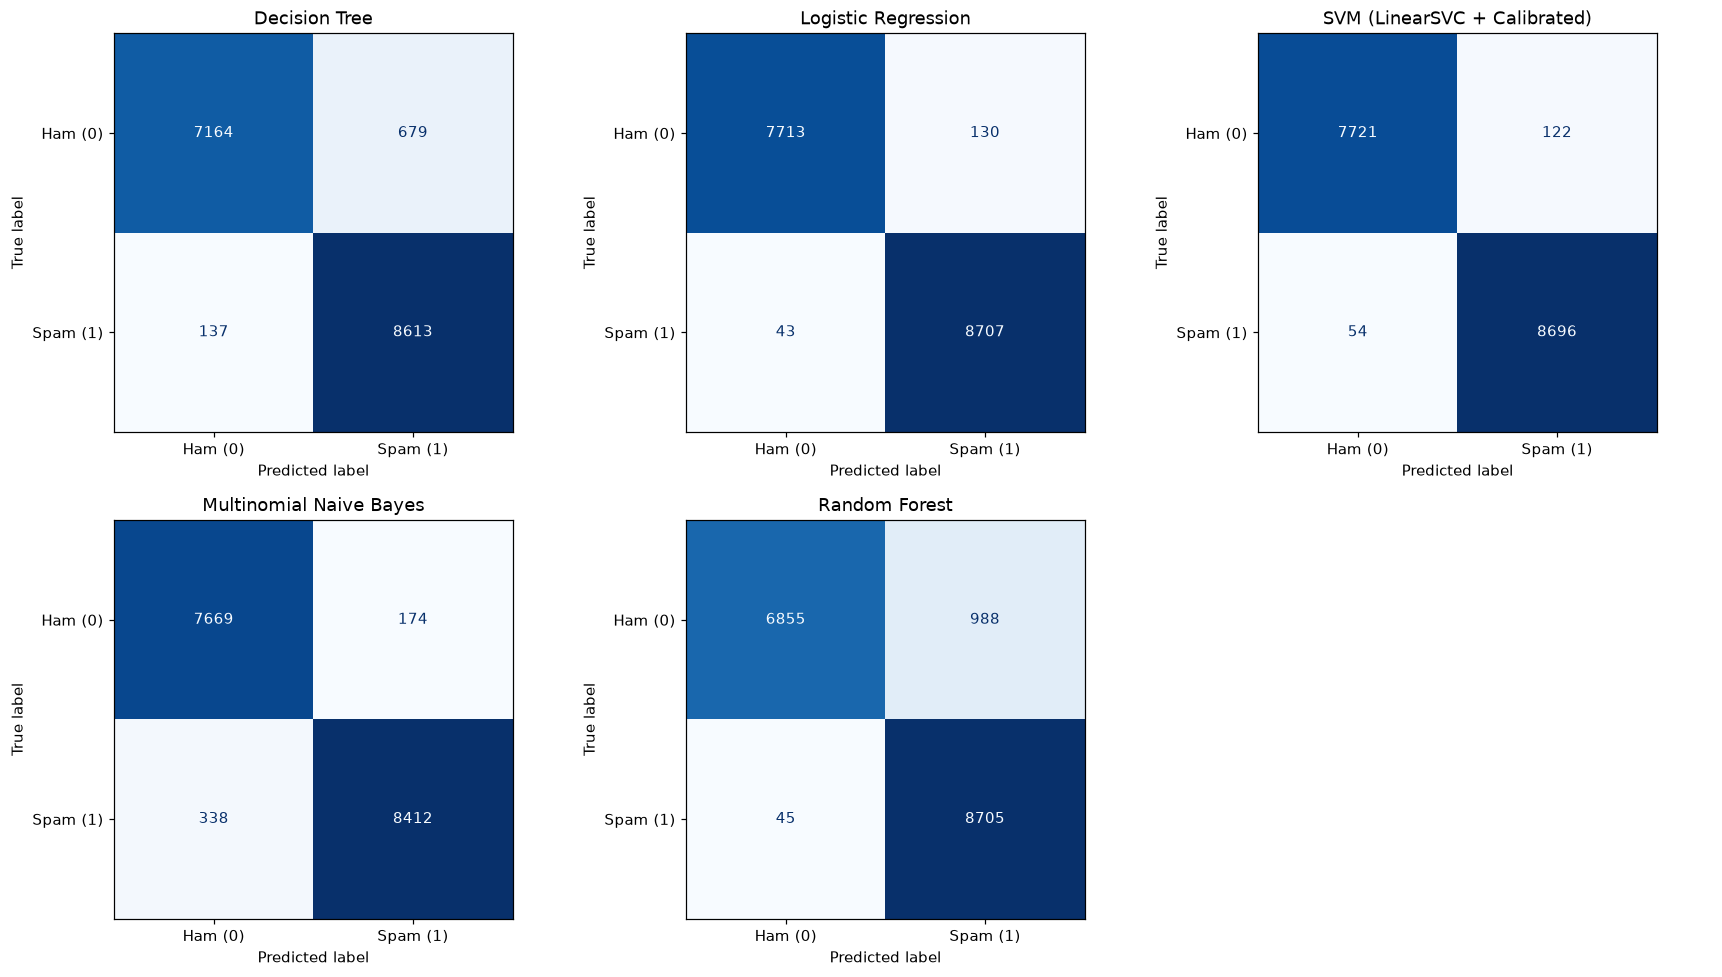

In [4]:
X_test, y_test = load_test_data()
n_models = len(MODEL_SPECS)
ncols = 3
nrows = (n_models + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4.5 * nrows))
axes_flat = axes.ravel()

for idx, spec in enumerate(MODEL_SPECS):
    ax = axes_flat[idx]
    with (MODELS_DIR / spec["filename"]).open("rb") as f:
        m = pickle.load(f)
    y_pred = m.predict(X_test)
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    disp = ConfusionMatrixDisplay(cm, display_labels=["Ham (0)", "Spam (1)"])
    disp.plot(cmap="Blues", values_format="d", ax=ax, colorbar=False)
    ax.set_title(spec["name"])

for idx in range(n_models, len(axes_flat)):
    axes_flat[idx].axis("off")

plt.tight_layout()
plt.show()

## 4. Kết luận

In [5]:
best = metadata["best_metrics"]
print("=============================================")
print(f"MÔ HÌNH CHÍNH ĐƯỢC CHỌN: {metadata['best_model_name']}")
print(f"  - Accuracy        : {best['accuracy']*100:.4f}%")
print(f"  - Precision (Spam): {best['precision_spam']*100:.4f}%")
print(f"  - Recall (Spam)   : {best['recall_spam']*100:.4f}%")
print(f"  - F1-Score (Spam) : {best['f1_spam']*100:.4f}%")
print(f"  - ROC-AUC         : {best['roc_auc']:.4f}")
print(f"  - Số mẫu đoán sai : {best['errors']:,} / {metadata['test_samples']:,}")
print(f"  - Đã lưu tại      : {metadata['best_model_path']}")
print("=============================================")

MÔ HÌNH CHÍNH ĐƯỢC CHỌN: Logistic Regression
  - Accuracy        : 98.9574%
  - Precision (Spam): 98.5289%
  - Recall (Spam)   : 99.5086%
  - F1-Score (Spam) : 99.0163%
  - ROC-AUC         : 0.9984
  - Số mẫu đoán sai : 173 / 16,593
  - Đã lưu tại      : models/best_model.pkl
